# Overview
This jupyter notebook covers the following contents:
1. Default configuration in LIBERO
2. Basic information about available LIBERO benchmarks
   - Get a dictionary of mapping from benchmark name to benchmark class
   - Check the integrity of benchmarks
   - Check the integrity of init files
   - Visualize all the init states of a task
   - Download datasets
   - Get information about a demonstration file and replay a trajectory


In [1]:
import sys
import os

# Load these before LIBERO imports simulator libraries
import torch
import torchvision

sys.path.insert(0, "/home/njmcmil/t2-project/LIBERO")

from libero.libero import benchmark, get_libero_path, set_libero_default_path
from termcolor import colored

## 1. Default file paths

All the paths are retrieved from a yaml config file located at `~/.libero/config.yaml`. And the default paths are set to relative to the libero codebase.

In [2]:
benchmark_root_path = get_libero_path("benchmark_root")
init_states_default_path = get_libero_path("init_states")
datasets_default_path = get_libero_path("datasets")
bddl_files_default_path = get_libero_path("bddl_files")
print("Default benchmark root path: ", benchmark_root_path)
print("Default dataset root path: ", datasets_default_path)
print("Default bddl files root path: ", bddl_files_default_path)

Default benchmark root path:  /home/njmcmil/t2-project/LIBERO/libero/libero
Default dataset root path:  /home/njmcmil/t2-project/LIBERO/libero/libero/../datasets
Default bddl files root path:  /home/njmcmil/t2-project/LIBERO/libero/libero/./bddl_files


# 2. See available benchmarks

### 2.1 Get a dictionary of mapping from benchmark name to benchmark class

In [3]:
benchmark_dict = benchmark.get_benchmark_dict()
print(benchmark_dict)

{'libero_spatial': <class 'libero.libero.benchmark.LIBERO_SPATIAL'>, 'libero_object': <class 'libero.libero.benchmark.LIBERO_OBJECT'>, 'libero_goal': <class 'libero.libero.benchmark.LIBERO_GOAL'>, 'libero_90': <class 'libero.libero.benchmark.LIBERO_90'>, 'libero_10': <class 'libero.libero.benchmark.LIBERO_10'>, 'libero_100': <class 'libero.libero.benchmark.LIBERO_100'>}


### 2.2 Check the integrity of benchmarks

In [4]:
# initialize a benchmark
benchmark_instance = benchmark_dict["libero_goal"]()

num_tasks = benchmark_instance.get_num_tasks()
# see how many tasks involved in the benchmark
print(f"{num_tasks} tasks in the benchmark {benchmark_instance.name}: ")

# Check if all the task names and their bddl file names
task_names = benchmark_instance.get_task_names()
print("The benchmark contains the following tasks:")
for i in range(num_tasks):
    task_name = task_names[i]
    task = benchmark_instance.get_task(i)
    bddl_file = os.path.join(bddl_files_default_path, task.problem_folder, task.bddl_file)
    print(f"\t {task_name}, detail definition stored in {bddl_file}")
    if not os.path.exists(bddl_file):
        print(colored(f"[error] bddl file {bddl_file} cannot be found. Check your paths", "red"))

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
10 tasks in the benchmark libero_goal: 
The benchmark contains the following tasks:
	 open_the_middle_drawer_of_the_cabinet, detail definition stored in /home/njmcmil/t2-project/LIBERO/libero/libero/./bddl_files/libero_goal/open_the_middle_drawer_of_the_cabinet.bddl
	 put_the_bowl_on_the_stove, detail definition stored in /home/njmcmil/t2-project/LIBERO/libero/libero/./bddl_files/libero_goal/put_the_bowl_on_the_stove.bddl
	 put_the_wine_bottle_on_top_of_the_cabinet, detail definition stored in /home/njmcmil/t2-project/LIBERO/libero/libero/./bddl_files/libero_goal/put_the_wine_bottle_on_top_of_the_cabinet.bddl
	 open_the_top_drawer_and_put_the_bowl_inside, detail definition stored in /home/njmcmil/t2-project/LIBERO/libero/libero/./bddl_files/libero_goal/open_the_top_drawer_and_put_the_bowl_inside.bddl
	 put_the_bowl_on_top_of_the_cabinet, detail definition stored in /home/njmcmil/t2-project/LIBERO/libero/libero/./bddl_files/libero_

### 2.3 Check the integrity of init files

In [5]:
import os
import torch

# Check if all the init states files exist for tasks
task_names = benchmark_instance.get_task_names()
print("The benchmark contains the following tasks:")
for i in range(num_tasks):
    task_name = task_names[i]
    task = benchmark_instance.get_task(i)
    init_states_path = os.path.join(init_states_default_path, task.problem_folder, task.init_states_file)
    if not os.path.exists(init_states_path):
        print(colored(f"[error] the init states {init_states_path} cannot be found. Check your paths", "red"))
print(f"An example of init file is named like this: {task.init_states_file}")

# Load torch init files
task = benchmark_instance.get_task(0)
init_states = torch.load(
    os.path.join(init_states_default_path, task.problem_folder, task.init_states_file),
    weights_only=False,
)
# Init states in the same (num_init_rollouts, num_simulation_states)
print(init_states.shape)


The benchmark contains the following tasks:
An example of init file is named like this: put_the_wine_bottle_on_the_rack.pruned_init
(50, 79)


### 2.4 Visualize all the init states of a task

[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /home/njmcmil/t2-project/.venv/lib/python3.10/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


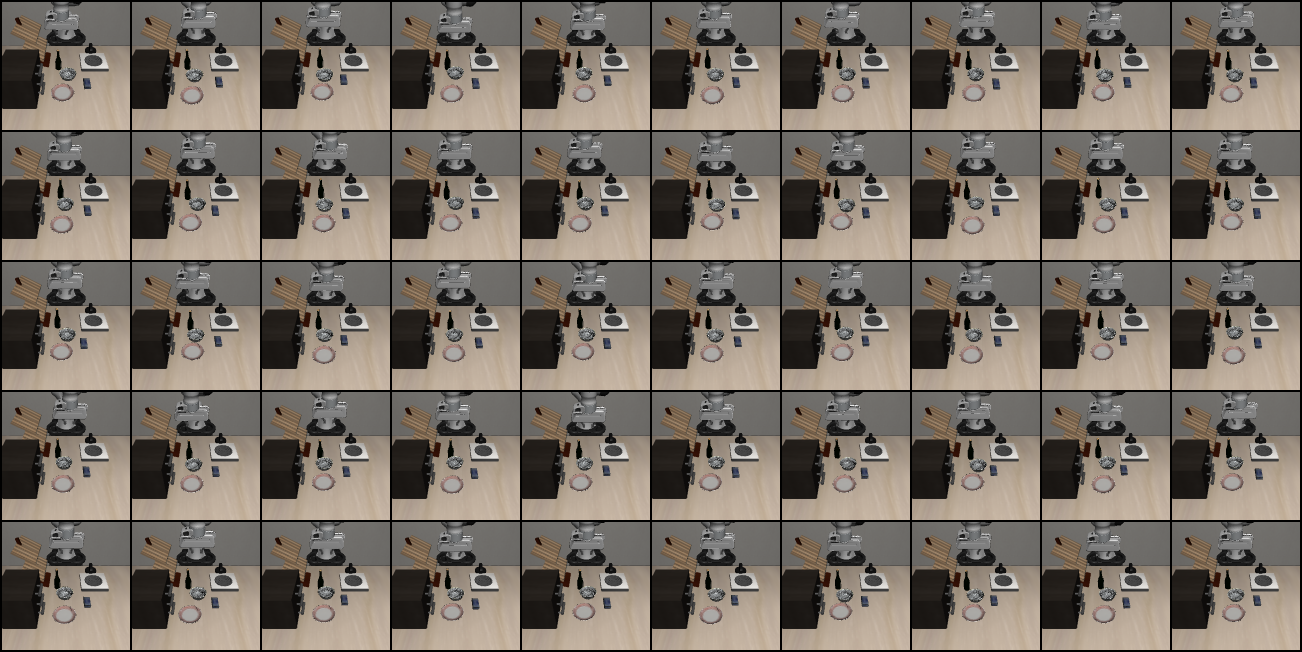

In [6]:
from libero.libero.envs import OffScreenRenderEnv
from IPython.display import display
from PIL import Image

import torch
import torchvision

# task_id is the (task_id + 1)th task in the benchmark
task_id = 8
task = benchmark_instance.get_task(task_id)

env_args = {
    "bddl_file_name": os.path.join(bddl_files_default_path, task.problem_folder, task.bddl_file),
    "camera_heights": 128,
    "camera_widths": 128
}

env = OffScreenRenderEnv(**env_args)


init_states = torch.load(
    os.path.join(init_states_default_path, task.problem_folder, task.init_states_file),
    weights_only=False,
)

# Fix random seeds for reproducibility
env.seed(0)

def make_grid(images, nrow=8, padding=2, normalize=False, pad_value=0):
    """Make a grid of images. Make sure images is a 4D tensor in the shape of (B x C x H x W)) or a list of torch tensors."""
    grid_image = torchvision.utils.make_grid(images, nrow=nrow, padding=padding, normalize=normalize, pad_value=pad_value).permute(1, 2, 0)
    return grid_image

images = []
env.reset()
for eval_index in range(len(init_states)):
    env.set_init_state(init_states[eval_index])

    for _ in range(5):
        obs, _, _, _ = env.step([0.] * 7)
    images.append(torch.from_numpy(obs["agentview_image"]).permute(2, 0, 1))

# # images = torch.stack(images, dim=0).permute(0, 3, 1, 2)
# print(images.shape)
grid_image = make_grid(images, nrow=10, padding=2, pad_value=0)
display(Image.fromarray(grid_image.numpy()[::-1]))
env.close()

### 2.5 Download datasets

In [7]:
# Select the project's task suite
benchmark_instance = benchmark_dict["libero_goal"]()
num_tasks = benchmark_instance.get_num_tasks()

# Find the dataset folder
datasets_default_path = get_libero_path("datasets")

# Build a list of demonstration file paths
demo_files = [
    os.path.join(
        datasets_default_path,
        benchmark_instance.get_task_demonstration(i),
    )
    for i in range(num_tasks)
]

# Check whether each file exists
for demo_file in demo_files:
    if os.path.exists(demo_file):
        print(f"FOUND: {demo_file}")
    else:
        print(f"MISSING: {demo_file}")

[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
FOUND: /home/njmcmil/t2-project/LIBERO/libero/libero/../datasets/libero_goal/open_the_middle_drawer_of_the_cabinet_demo.hdf5
FOUND: /home/njmcmil/t2-project/LIBERO/libero/libero/../datasets/libero_goal/put_the_bowl_on_the_stove_demo.hdf5
FOUND: /home/njmcmil/t2-project/LIBERO/libero/libero/../datasets/libero_goal/put_the_wine_bottle_on_top_of_the_cabinet_demo.hdf5
FOUND: /home/njmcmil/t2-project/LIBERO/libero/libero/../datasets/libero_goal/open_the_top_drawer_and_put_the_bowl_inside_demo.hdf5
FOUND: /home/njmcmil/t2-project/LIBERO/libero/libero/../datasets/libero_goal/put_the_bowl_on_top_of_the_cabinet_demo.hdf5
FOUND: /home/njmcmil/t2-project/LIBERO/libero/libero/../datasets/libero_goal/push_the_plate_to_the_front_of_the_stove_demo.hdf5
FOUND: /home/njmcmil/t2-project/LIBERO/libero/libero/../datasets/libero_goal/put_the_cream_cheese_in_the_bowl_demo.hdf5
FOUND: /home/njmcmil/t2-project/LIBERO/libero/libero/../datasets/libero_goal

### 2.6 Get information about a demonstration file and replay a trajectory

In [8]:
import h5py
from libero.libero.utils.dataset_utils import get_dataset_info
from IPython.display import HTML
import imageio

example_demo_file = os.path.join(
    get_libero_path("datasets"),
    "libero_goal",
    "put_the_bowl_on_the_plate_demo.hdf5",
)
# Print the dataset info. We have a standalone script for doing the same thing available at `scripts/get_dataset_info.py`
get_dataset_info(example_demo_file)

with h5py.File(example_demo_file, "r") as f:
    images = f["data/demo_0/obs/agentview_rgb"][()]

video_writer = imageio.get_writer("output.mp4", fps=60)
for image in images:
    video_writer.append_data(image[::-1])
video_writer.close()

HTML("""
    <video width="640" height="480" controls>
        <source src="output.mp4" type="video/mp4">
    </video>
    <script>
        var video = document.getElementsByTagName('video')[0];
        video.playbackRate = 2.0; // Increase the playback speed to 2x
        </script>    
""")


total transitions: 4669
total trajectories: 50
traj length mean: 93.38
traj length std: 9.212795449807837
traj length min: 79
traj length max: 126
action min: -1.0
action max: 1.0
language instruction: put the bowl on the plate

==== Filter Keys ====
no filter keys


==== Env Meta ====
{
    "type": 1,
    "env_name": "Libero_Tabletop_Manipulation",
    "problem_name": "libero_tabletop_manipulation",
    "bddl_file": "chiliocosm/bddl_files/libero_goal/put_the_bowl_on_the_plate.bddl",
    "env_kwargs": {
        "robots": [
            "Panda"
        ],
        "controller_configs": {
            "type": "OSC_POSE",
            "input_max": 1,
            "input_min": -1,
            "output_max": [
                0.05,
                0.05,
                0.05,
                0.5,
                0.5,
                0.5
            ],
            "output_min": [
                -0.05,
                -0.05,
                -0.05,
                -0.5,
                -0.5,
      

### 2.7 Concate multiple datasets for multit-task training

In [9]:
from torch.utils.data import ConcatDataset, Dataset
from libero.lifelong.datasets import get_dataset, SequenceVLDataset

num_tasks = benchmark_instance.get_num_tasks()
print(f"Number of tasks in the benchmark {benchmark_instance.name}: {num_tasks}")

# manip_datasets = []
# for demo_file in demo_files:
#     task_i_dataset, shape_meta = get_dataset(
#             dataset_path=os.path.join(cfg.folder,
#                                         benchmark.get_task_demonstration(i)),
#             obs_modality=cfg.data.obs.modality,
#             initialize_obs_utils=(i==0),
#             seq_len=cfg.data.seq_len)    
#     manip_datasets.append()

# concat_dataset = ConcatDataset([get_dataset(demo_file) for demo_file in demo_files])

Number of tasks in the benchmark libero_goal: 10


### 2.8 Create datasets for Experience Replay algorithm

In the algorithm of ER, we need to sample data from both dataset of the current task and data from previous experiences. To this end, a specific implementation is needed (`TruncatedSequenceDataset`).